# Denver crime data: what was wrong with it, and how it was fixed

This notebook walks through the cleaning of a public police dataset, end to end: the raw file,
the problems hiding in it, the fix for each one, and what the clean data then shows.

**The data.** The City and County of Denver publishes every reported criminal offense through its
[Open Data Catalog](https://opendata-geospatialdenver.hub.arcgis.com/datasets/geospatialDenver::crime/about),
following the FBI's NIBRS standard. It covers the previous five calendar years plus the current one, and is
updated Monday to Friday.

**One row = one offense**, with where and when it happened, when it was reported, and what type of crime it was.
One police *incident* can produce several offense rows, which matters later.

Everything below runs on a single downloaded snapshot. Every number is produced by the code in this
notebook — nothing is typed in by hand. The analysis code lives in the `denvercrime` package in this
repository; the notebook only calls it and explains the results.

## Setup

Load the project configuration and the raw snapshot. The configuration file
(`configs/default.toml`) holds every cleaning rule, so the rules are reviewable in one place
rather than buried in code.

Police data is not kept in this repository. To re-run this notebook, fetch a snapshot first with
`python -m denvercrime download`; the numbers below will then describe that snapshot rather than this one.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

from denvercrime.config import DEFAULT_CONFIG, load_config
from denvercrime.data.load import find_latest_raw, load_raw

pd.set_option("display.max_columns", 50, "display.width", 120)

ROOT = DEFAULT_CONFIG.parent.parent          # repository root; keeps printed paths relative
cfg = load_config()

snapshot = find_latest_raw(cfg.data.raw_dir)
meta = json.loads(snapshot.with_suffix(".json").read_text())
raw = load_raw(snapshot)

print(f"snapshot file   : {snapshot.relative_to(ROOT).as_posix()}")
print(f"downloaded      : {meta['downloaded_at_utc'][:10]}")
print(f"offense rows    : {len(raw):,}")
print(f"columns         : {raw.shape[1]}")
print(f"offenses occurred between {raw['FIRST_OCCURRENCE_DATE'].min():%d %b %Y}"
      f" and {raw['FIRST_OCCURRENCE_DATE'].max():%d %b %Y}")

snapshot file   : data/raw/crime_20260918T115808Z.parquet
downloaded      : 2026-09-18
offense rows    : 379,705
columns         : 21
offenses occurred between 01 Jan 2021 and 14 Sep 2026


## 1. A first look at the raw data

Before changing anything, look at what arrived: how many columns of each type, and a few real rows.

In [2]:
print("column types:")
print(raw.dtypes.value_counts().to_string())

preview = ["OFFENSE_CATEGORY_ID", "OFFENSE_TYPE_ID", "FIRST_OCCURRENCE_DATE",
           "LAST_OCCURRENCE_DATE", "REPORTED_DATE", "INCIDENT_ADDRESS",
           "NEIGHBORHOOD_ID", "GEO_LAT", "GEO_LON"]
display(raw[preview].head(5))

column types:
string            9
Int64             5
datetime64[ms]    3
float64           3
int64             1


,OFFENSE_CATEGORY_ID,OFFENSE_TYPE_ID,FIRST_OCCURRENCE_DATE,LAST_OCCURRENCE_DATE,REPORTED_DATE,INCIDENT_ADDRESS,NEIGHBORHOOD_ID,GEO_LAT,GEO_LON
0,public-disorder,criminal-mischief-other,2021-10-18 00:05:00,NaT,2021-10-18 00:05:00,3000 BLK STOUT ST,five-points,39.759718,-104.975488
1,public-disorder,criminal-mischief-other,2025-11-22 22:33:00,NaT,2025-11-22 22:33:00,3200 BLK W 14TH AVE,west-colfax,39.738670,-105.028774
2,public-disorder,criminal-mischief-other,2021-08-25 05:05:00,2021-08-25 05:11:00,2021-08-25 05:53:00,1525 17TH ST,union-station,39.751958,-104.998351
3,public-disorder,criminal-mischief-other,2022-09-04 04:00:00,NaT,2022-09-04 04:19:00,5885 E STAPLETON N DR,northeast-park-hill,39.779522,-104.918893
4,public-disorder,criminal-mischief-other,2025-05-13 22:00:00,NaT,2025-05-13 22:11:00,4801 N PECOS ST,chaffee-park,39.784137,-105.006842


### Missing values

Most columns are complete. The gaps that matter are `LAST_OCCURRENCE_DATE` (many offenses are a single
moment, so there is nothing to record) and a small number of rows with no map coordinates.

In [3]:
from denvercrime.data.profile import missing_value_table

missing_value_table(raw)

,dtype,missing,missing_pct
column,,,
LAST_OCCURRENCE_DATE,datetime64[ms],178298,46.96
NEIGHBORHOOD_ID,string,376,0.10
DISTRICT_ID,string,34,0.01
GEO_LAT,float64,1,0.00
GEO_LON,float64,1,0.00
FIRST_OCCURRENCE_DATE,datetime64[ms],0,0.00
GEO_X,Int64,0,0.00
GEO_Y,Int64,0,0.00
INCIDENT_ADDRESS,string,0,0.00


## 2. What was wrong, and how it was fixed

Six issues had to be dealt with before the data could be counted reliably. The project's cleaner applies
all of them in one pass, and records what each step removed, so the effect of every rule is auditable.

In [4]:
from denvercrime.data.clean import clean_offenses

offenses, report = clean_offenses(raw, cfg)

print(f"most recent report in the file : {report.as_of}")
print(f"cleaning keeps offenses before : {report.cutoff}")
print(f"offense rows after cleaning    : {len(offenses):,}")

most recent report in the file : 2026-09-14
cleaning keeps offenses before : 2026-08-15
offense rows after cleaning    : 351,132


### 2.1 Coordinates that are not in Denver

Every offense is mapped to a hexagon, so a row with a missing or impossible location cannot be used.
A small number of rows have no coordinates at all, and a few sit outside the city's bounding box.

In [5]:
box = cfg.data.bbox
missing_coords = raw["GEO_LAT"].isna() | raw["GEO_LON"].isna()
inside = raw["GEO_LAT"].between(box.min_lat, box.max_lat) & raw["GEO_LON"].between(box.min_lon, box.max_lon)

print(f"rows with usable coordinates inside Denver : {inside.sum():,}")
print(f"removed, no coordinates recorded           : {missing_coords.sum():,}")
print(f"removed, coordinates outside the city      : {(~inside & ~missing_coords).sum():,}")

rows with usable coordinates inside Denver : 379,506
removed, no coordinates recorded           : 1
removed, coordinates outside the city      : 198


### 2.2 Places where crime is recorded, not committed

This is the issue that changes results the most. The busiest "crime locations" in the raw file are not
street corners: they are the police headquarters, two jails, the city's trauma hospital, and the airport.
Offenses get *filed* at those addresses, so leaving them in makes them look like permanent crime hotspots.

Each place below was checked individually before being excluded, and the reason is stored in the
configuration file next to the rule.

In [6]:
from denvercrime.data.profile import excluded_places_table

places = excluded_places_table(cfg, report)
display(places)
print(f"offense rows removed by these five rules: {places['offense_rows_removed'].sum():,}"
      f"  ({places['offense_rows_removed'].sum() / len(raw):.1%} of the file)")

,place,kind,offense_rows_removed,reason
0,dia,neighbourhood,18822,Denver International Airport: 5% of all incide...
1,490 W COLFAX AVE,address,1862,Downtown Detention Center (Van Cise-Simonet): ...
2,1331 N CHEROKEE ST,address,1364,Denver Police headquarters: 95% 'all-other-cri...
3,777 N BANNOCK ST,address,828,"Denver Health, the city's Level I trauma centr..."
4,10500 E SMITH RD,address,253,Denver County Jail: offenses inside the jail


offense rows removed by these five rules: 23,129  (6.1% of the file)


### 2.3 The timestamp bug: offenses that end before they start

The city offers the same data as a CSV download. In that export, two of the three timestamps
(`FIRST_OCCURRENCE_DATE` and `REPORTED_DATE`) are shifted **+7 hours**, while `LAST_OCCURRENCE_DATE` is not.
The result is thousands of offenses that appear to finish before they began — and every "time of day"
figure drawn from that file is wrong by seven hours.

The check below is what makes it visible. An offense must satisfy *start ≤ end*, so counting the rows
that break that rule measures the damage. Below, the API snapshot (which is correct) is deliberately
shifted to reproduce the CSV export, then the loader's automatic correction is applied.

correction the loader works out on its own: -7 hours


,shift_hours,violations,violation_pct,comparable_rows
0,0.0,98872,49.09,201407
1,-6.0,61029,30.30,201407
2,-7.0,0,0.00,201407


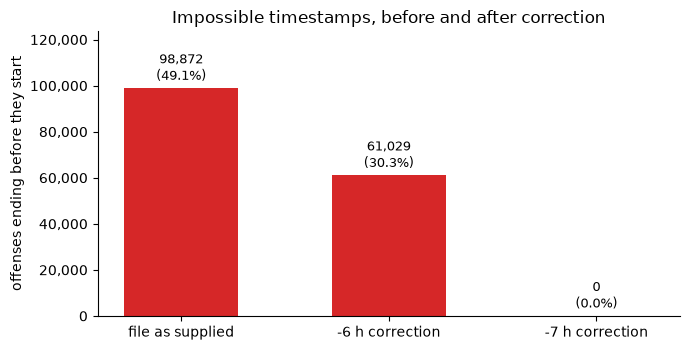

In [7]:
from denvercrime.data.load import apply_time_shift, detect_time_shift, order_violation_summary
from denvercrime.viz.quality import plot_timestamp_violations

as_exported = apply_time_shift(raw, 7)        # reproduce the city's CSV export from the correct data
summary = order_violation_summary(as_exported)

print(f"correction the loader works out on its own: {detect_time_shift(as_exported):+g} hours")
display(summary)
plot_timestamp_violations(summary)

### 2.4 Offense rows are not incidents

One police incident can produce several offense rows — a burglary and a theft from the same break-in, for
example. Counting rows would count that event twice. The cleaner collapses offenses into one record per
incident per crime group, taking the time and place from the earliest offense.

In [8]:
from denvercrime.data.clean import to_incidents

incidents = to_incidents(offenses)
rows_per_incident = offenses.groupby("INCIDENT_ID").size()
multi = rows_per_incident[rows_per_incident > 1]

print(f"offense rows                        : {len(offenses):,}")
print(f"distinct incidents                  : {len(rows_per_incident):,}")
print(f"incidents with more than one offense: {len(multi):,}  ({len(multi) / len(rows_per_incident):.1%}"
      f" of incidents, {multi.sum() / len(offenses):.1%} of rows)")
print(f"incident-group records kept         : {len(incidents):,}")

offense rows                        : 351,132
distinct incidents                  : 328,378
incidents with more than one offense: 19,311  (5.9% of incidents, 12.0% of rows)
incident-group records kept         : 342,796


### 2.5 The most recent weeks are still filling up

Police records are updated for weeks after an event: some crimes are reported late, and investigations add
detail. Counting the newest weeks as if they were complete would show a fake decline at the end of every
chart, so the final 30 days of the snapshot are dropped.

In [9]:
reporting_lag = (raw["REPORTED_DATE"] - raw["FIRST_OCCURRENCE_DATE"]).dt.days

for days in (1, 7, 30, 90):
    print(f"reported more than {days:>2} days after the offense : {(reporting_lag > days).mean():6.2%}")
print(f"\ndays of data excluded as incomplete        : {cfg.data.drop_recent_days}")

reported more than  1 days after the offense : 19.26%
reported more than  7 days after the offense :  7.77%
reported more than 30 days after the offense :  2.70%
reported more than 90 days after the offense :  0.98%

days of data excluded as incomplete        : 30


### 2.6 Offenses that span a long period

Some offenses have no exact moment — a burglary discovered after a two-week holiday, say. They are kept,
counted in the week they started, and reported, so the choice is visible rather than silent.

In [10]:
print(f"offenses spanning more than {cfg.cleaning.long_window_days} days : "
      f"{report.long_window_offenses:,}  ({report.long_window_offenses / len(raw):.1%} of all rows)")

offenses spanning more than 7 days : 10,434  (2.7% of all rows)


## 3. The cleaning funnel

Every rule above, in the order it is applied, with the rows it removed.

,step,rows,removed,pct_of_raw
0,raw offenses,379705,0,100.0
1,IS_CRIME = 1 and IS_TRAFFIC = 0,379705,0,100.0
2,valid coordinates inside Denver bbox,379506,199,99.9
3,excluded neighbourhoods,360684,18822,95.0
4,excluded institutional addresses,356377,4307,93.9
5,"occurred in [2021-01-04, 2026-08-15)",351132,5245,92.5
6,category mapped to a group,351132,0,92.5


incident-group records after collapsing offenses to incidents: 342,796


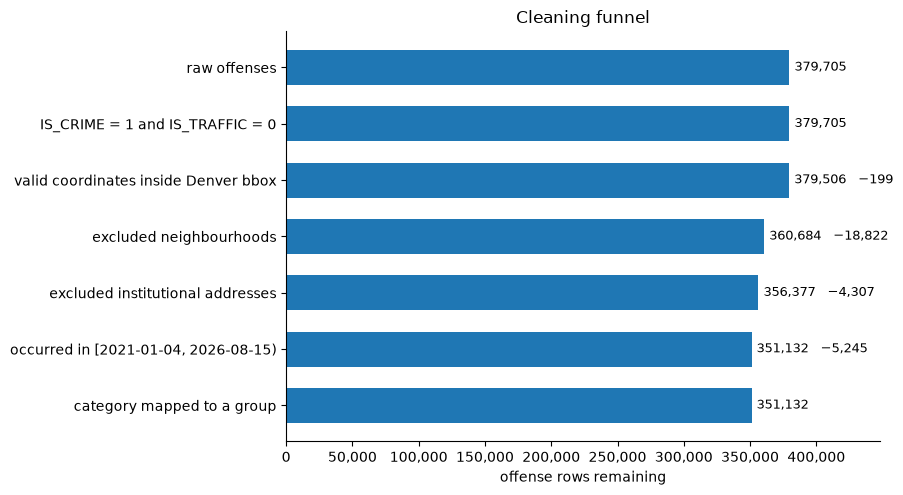

In [11]:
from denvercrime.data.profile import funnel_table
from denvercrime.viz.quality import plot_cleaning_funnel

funnel = funnel_table(report)
display(funnel)
print(f"incident-group records after collapsing offenses to incidents: {len(incidents):,}")
plot_cleaning_funnel(funnel)

## 4. What the clean data shows

With the data trustworthy, four questions are worth asking: is crime rising or falling, does it have a
season, is it concentrated, and do the busy places stay busy?

The next cell runs the full preparation step, which applies the cleaning above and counts incidents onto a
grid of equal-area hexagons, one row per hexagon per week.

Only whole weeks are counted, so incidents in the part-week at the end of the snapshot are left out. That
is why the panel holds slightly fewer records than the cleaning step produced.

In [12]:
from denvercrime import pipeline

prepared = pipeline.prepare(cfg)
panel, _ = pipeline.load_features(cfg)
in_panel = sum(prepared["incidents_by_group"].values())

print(f"hexagons           : {prepared['cells']}  (mean {panel['area_km2'].mean():.2f} sq km each)")
print(f"whole weeks        : {prepared['weeks']}  ({prepared['first_week']} to {prepared['last_week']})")
print(f"hexagon-week rows  : {len(panel):,}")
print(f"incident-group records in the panel: {in_panel:,}"
      f"  ({len(incidents) - in_panel:,} fell in the final part-week)")
print("by group           : " + ", ".join(f"{k} {v:,}" for k, v in prepared["incidents_by_group"].items()))

hexagons           : 430  (mean 0.80 sq km each)
whole weeks        : 292  (2021-01-04 to 2026-08-03)
hexagon-week rows  : 125,560
incident-group records in the panel: 341,954  (842 fell in the final part-week)
by group           : property 190,971, society 71,161, other 45,363, person 34,459


### Property crime has fallen; crime against people has not

Each bar is the average number of incidents per week in that year, so the partial final year stays
comparable with the rest.

,property,person,society,other
week,,,,
2021,731.3,108.4,221.6,130.6
2022,802.1,118.1,260.3,139.3
2023,674.6,120.9,254.8,150.4
2024,604.5,120.8,243.4,166.1
2025,541.0,117.5,236.7,169.8
2026,512.6,124.8,245.6,188.7


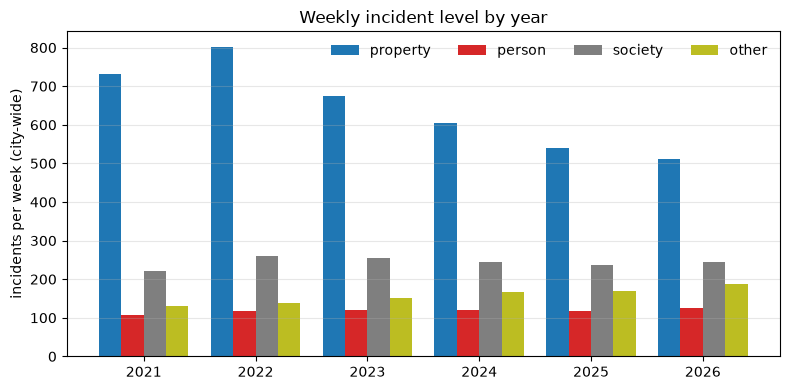

In [13]:
from denvercrime.viz import explore as ex

groups, targets = list(cfg.groups), list(cfg.model.targets)
weekly = ex.weekly_totals(panel, groups)

display(ex.level_by_year(weekly).round(1))
ex.plot_trend_by_year(weekly, groups)

### Crime against people has a summer season; property crime barely moves

The line shows each month's average divided by its own year's average, so 1.0 is an ordinary month.

,property,person
week,,
1,1.02,0.88
2,0.98,0.87
3,0.94,0.89
4,0.98,0.93
5,1.00,1.04
6,1.02,1.15
7,1.04,1.14
8,1.01,1.10
9,1.03,1.12


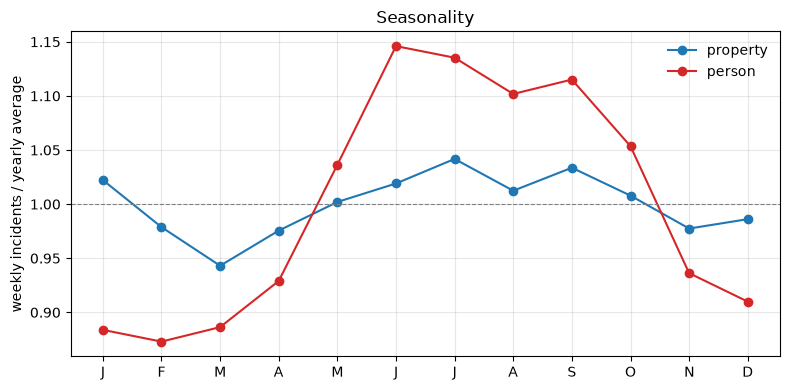

In [14]:
display(ex.seasonality_index(weekly)[targets].round(2))
ex.plot_seasonality(weekly, targets)

### Crime is concentrated in a small part of the city

Hexagons are sorted from busiest to quietest. The curve shows how much of the city you need to cover to
account for a given share of incidents; the dashed line is what an evenly spread city would look like.

,area_share_holding_50pct,incident_share_in_top_5pct_area
target,,
property,0.163,0.246
person,0.108,0.365


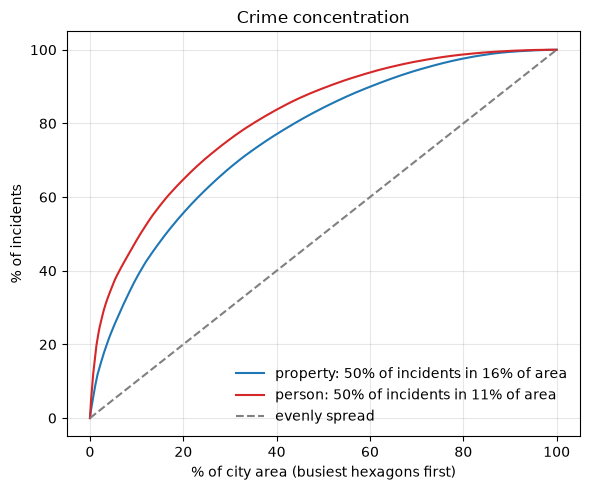

In [15]:
display(ex.concentration_table(panel, targets).round(3))
ex.plot_concentration(panel, targets)

### The busy places stay busy

Comparing one year with the next: a rank correlation near 1.0 means the order of hexagons barely changes,
and the overlap is the share of the busiest 5% of hexagons that are still in the busiest 5% a year later.
This is why a forecast has to beat a simple long-run average to be worth anything.

,years,spearman,top5pct_overlap,target
0,2021->2022,0.965,0.864,property
1,2022->2023,0.967,0.818,property
2,2023->2024,0.956,0.818,property
3,2024->2025,0.955,0.818,property
4,2021->2022,0.880,0.818,person
5,2022->2023,0.889,0.864,person
6,2023->2024,0.880,0.864,person
7,2024->2025,0.901,0.773,person


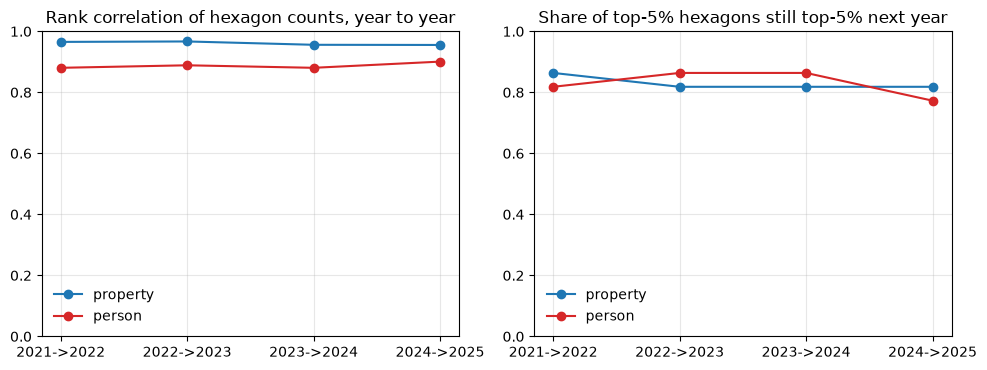

In [16]:
display(ex.stability_table(panel, targets).round(3))
ex.plot_hotspot_stability(panel, targets)

## 5. Key findings

Every figure below is printed by a cell above, from the snapshot named at the top of this notebook.

- **One row in sixteen is filed where the crime did not happen.** Five rules — the airport neighbourhood
  and four institutional addresses — remove 23,129 offense rows, 6.1% of the file. Left in, they look like
  the city's most reliable hotspots.
- **The city's CSV export has a seven-hour timestamp error** that leaves thousands of offenses apparently
  ending before they start. The loader detects and corrects it automatically; any analysis of time of day
  that skips this step is wrong by seven hours.
- **Counting rows instead of incidents inflates the totals.** 5.9% of incidents produce more than one
  offense row, and those incidents account for 12% of all rows, so a plain row count double-counts them.
- **Property crime fell by about a third while crime against people did not** — roughly 802 incidents a
  week in 2022 against 541 in 2025, while crime against people stayed near 120. A single "total crime"
  number would hide two opposite trends.
- **Crime is concentrated and stays put.** Half of all property incidents occur in 16% of the city's area
  (11% for crime against people), and year-to-year rank correlation between hexagons is about 0.96 and
  0.89. Any forecast has to beat a long-run average to be worth building.

## 6. Where this goes next

The clean hexagon-week table is the input to the forecasting part of this project, which predicts next
week's incident count for every hexagon and is tested on future weeks it has never seen, against six naive
baselines. The method and the results are in the
[repository README](../README.md#4-method) — including the finding that for crime against people, a simple
long-run average matches the trained model, which follows directly from how stable the hotspots are above.